# 10 · Simulate a campaign

**Step 0 of the workflow.** Nothing here organises anything — this is a
campaign writing files, the way a campaign does. Run it once; `11` and `12`
use what it leaves behind.

The campaign is an **A–B alloy nanocatalyst library** — A and B are
fictional metals, tested in a generic electro-reduction: eight alloys from
pure A to pure B, plus one
synthesis that failed, characterised the way a real campaign would be —
fifteen techniques across four stages, by different people, on different
instruments, in different rooms.

| stage | what was done |
|---|---|
| **synthesis** | the recipe — composition, reagents, conditions; one run aborted |
| **characterization** | UV-Vis (in-situ growth), EDS, XPS, Raman, IR, SAXS, WAXS, 2D SAXS, XAS, XPCS — and TEM, SEM, DLS, tomography |
| **testing** | the reduction, hydrogen and oxygen evolution, product Faradaic efficiencies |
| **computation** | DFT: density of states, *P and H adsorption energies |

**Everything follows from one hidden number per sample — the B atomic
fraction *x*.** Fifteen techniques see fifteen different shadows of it, so
measurements that never met can be checked against each other, and — because
this is simulated — against the truth.

```
../OrgDemo/Demo/             beside this repository
├── MetaData/                four *_dict.py, one per stage, keyed by sample id
├── RawSpectra/              UV-Vis growth series — every sample in one folder
├── Spectroscopy/  Scattering/  Dynamics/  Electrochemistry/  Computation/
├── TEMData/  SEMData/  DLSData/  TomoData/     ← nobody wrote these down
├── truth.csv                the answer key (this notebook)
├── demo.json                the organizer (notebook 11)
└── results/                 stored fits (notebook 12)
```

Every path the metadata records is **relative to this folder**, and the
organizer `11` builds sits inside it and links relative too — so the whole
folder is portable as one piece: copy it, zip it, open it on another machine.

The generator is `pyDataOrg.demo.build_showcase_project`. The web app's
**🎓 Demo** page and `python -m pyDataOrg.demo --campaign` call the same
function, so all three routes write identical files.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pyDataOrg import structure
from pyDataOrg.core.pathmap import display_path
from pyDataOrg.demo import build_showcase_project, demo_root, showcase_truth
from pyDataOrg.demo import materials as mat
from pyDataOrg.viz import plots

ROOT = demo_root("Demo")          # ../OrgDemo/Demo beside the repository, or $PYDATAORG_DEMO_ROOT

# The hidden number, one per sample. S09 is the failed run and has none.
fractions = {mat.sample_id(i): x for i, x in enumerate(mat.DEFAULT_FRACTIONS, start=1)}
fractions

{'S01': 0.0,
 'S02': 0.1,
 'S03': 0.25,
 'S04': 0.4,
 'S05': 0.55,
 'S06': 0.7,
 'S07': 0.85,
 'S08': 1.0}

## One number, fifteen shadows

The two (fictional) metals are taken to mix at every composition, so the
textbook consequences arrive together. These are the generator's own functions
(`pyDataOrg.demo.materials`), drawn before a single file exists:

* the **lattice parameter** follows Vegard's law, so a diffraction peak
  measures composition;
* the particles keep **one plasmon band** that moves from ~600 to ~540 nm —
  the evidence of an alloy; a mixture of A and B particles would show two
  fixed bands instead;
* **three sizes disagree for a reason**: TEM sees primary particles, DLS the
  solvated object weighted by d⁶, XPCS the loose aggregates of the ink;
* B **segregates to the surface**, so XPS (top nanometres) reads richer in
  B than EDS (the whole particle);
* the **d-band centre** sets how strongly the intermediate *P binds, and the
  P partial current
  is a **Sabatier volcano** in that binding energy — the reason anyone builds
  a composition series in the first place.

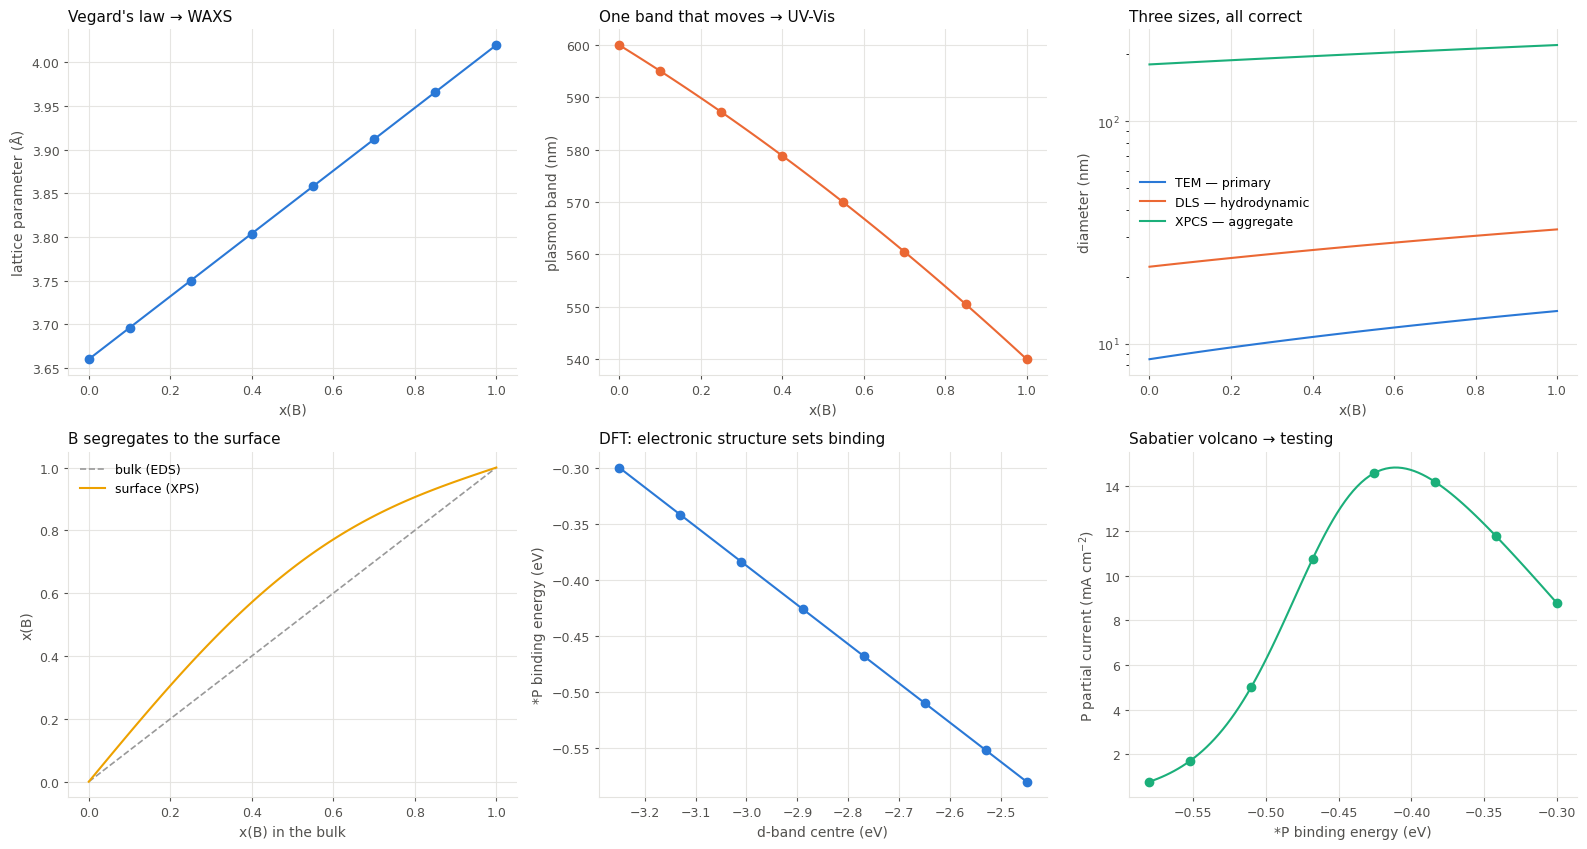

In [2]:
x = np.linspace(0.0, 1.0, 101)
xs = np.array(list(fractions.values()))
blue, orange, aqua, yellow = plots.CATEGORICAL[:4]

fig, axes = plt.subplots(2, 3, figsize=(16, 8.6))
(a, b, c), (d, e, f) = axes

a.plot(x, mat.lattice_parameter_A(x), color=blue)
a.plot(xs, mat.lattice_parameter_A(xs), "o", color=blue)
plots.style(a, "x(B)", "lattice parameter (Å)", "Vegard's law → WAXS")

b.plot(x, mat.lspr_nm(x), color=orange)
b.plot(xs, mat.lspr_nm(xs), "o", color=orange)
plots.style(b, "x(B)", "plasmon band (nm)", "One band that moves → UV-Vis")

for curve, colour, label in ((mat.particle_diameter_nm, blue, "TEM — primary"),
                             (mat.hydrodynamic_nm, orange, "DLS — hydrodynamic"),
                             (mat.aggregate_nm, aqua, "XPCS — aggregate")):
    c.plot(x, [curve(v) for v in x], color=colour, label=label)
c.set_yscale("log")
plots.style(c, "x(B)", "diameter (nm)", "Three sizes, all correct")
c.legend(frameon=False, fontsize=9)

d.plot(x, x, "--", color="0.6", lw=1.2, label="bulk (EDS)")
d.plot(x, [mat.surface_b_fraction(v) for v in x], color=yellow, label="surface (XPS)")
plots.style(d, "x(B) in the bulk", "x(B)", "B segregates to the surface")
d.legend(frameon=False, fontsize=9)

e.plot(mat.d_band_centre_eV(x), mat.p_binding_eV(x), color=blue)
e.plot(mat.d_band_centre_eV(xs), mat.p_binding_eV(xs), "o", color=blue)
plots.style(e, "d-band centre (eV)", "*P binding energy (eV)",
            "DFT: electronic structure sets binding")

f.plot(mat.p_binding_eV(x), [mat.p_partial_current(v) for v in x], color=aqua)
f.plot(mat.p_binding_eV(xs), [mat.p_partial_current(v) for v in xs], "o", color=aqua)
plots.style(f, "*P binding energy (eV)", "P partial current (mA cm$^{-2}$)",
            "Sabatier volcano → testing")
fig.tight_layout()

## Write it

One call writes the whole campaign — curves, micrographs, a tomogram, detector
images, correlation functions, electrochemistry, DFT output, and the metadata
the operators kept. Re-running overwrites it with the same numbers; it only
ever deletes a folder it made itself, so pointing it at real data cannot.

In [3]:
start = time.perf_counter()
build_showcase_project(ROOT)
print(f"wrote {display_path(ROOT)} in {time.perf_counter() - start:.1f} s\n")

print(structure.tree(ROOT, depth=1))

wrote ../../OrgDemo/Demo in 0.7 s

📁 Demo  11 folders · 1 file · .txt 1 · 1 hidden
├── 📁 Computation  8 folders
├── 📁 DLSData  8 folders
├── 📁 Dynamics  3 folders
├── 📁 Electrochemistry  8 folders
├── 📁 MetaData  4 files · .py 4
├── 📁 RawSpectra  1 folder
├── 📁 Scattering  8 folders
├── 📁 SEMData  8 folders
├── 📁 Spectroscopy  8 folders
├── 📁 TEMData  8 folders
├── 📁 TomoData  2 folders
└── 📄 README.txt  1.2 KB


## What the people wrote down

Four metadata modules, one per stage, each a dict keyed by sample id. A block
that **names files** becomes a measurement when it is ingested; everything
else is kept as a parameter. Here is one sample's characterization record —
`structure.tree` descends into a Python module the same way it descends into a
folder, without loading any data.

In [4]:
print(structure.tree(
    f"{ROOT}/MetaData/Characterization_dict.py::Characterization_dict/S05",
    depth=2, limit=5))

# The files it names are relative to the campaign folder — no machine's
# absolute path is baked in.
print(structure.tree(
    f"{ROOT}/MetaData/Characterization_dict.py::Characterization_dict/S05/WAXS/files",
    depth=1))

🔑 S05
├── · sample_id  str = S05
├── 🔑 characterization_batch  5 keys
│   ├── · run_id  str = char_05
│   ├── · batch_tag  str = library_2
│   ├── · campaign  str = AB-library
│   ├── · status  str = done
│   └── · started_at  str = 2026-04-08T11:00:00
├── 🔑 UVVis  7 keys
│   ├── · modality  str = uvvis
│   ├── · instrument  str = DemoSpec HR4000
│   ├── · note  str = in-situ growth series; the last frame is the product
│   ├── · n_frames  int = 14
│   ├── · path_length_mm  float = 10
│   └── … +2 more  raise the per-layer limit to see them
├── 🔑 EDS  7 keys
│   ├── · modality  str = eds
│   ├── · instrument  str = DemoSEM + 100 mm2 SDD
│   ├── · beam_energy_keV  float = 20
│   ├── · quantification  str = Cliff-Lorimer
│   ├── · k_factor_B_La_over_A_Ka  float = 0.85
│   └── … +2 more  raise the per-layer limit to see them
├── 🔑 XPS_A2p  7 keys
│   ├── · modality  str = xps
│   ├── · instrument  str = DemoXPS
│   ├── · source  str = Al Ka 1486.6 eV
│   ├── · pass_energy_eV  float = 20
│

## What nobody wrote down

Four techniques arrived as folders dropped on a share — a folder per sample,
and no record anywhere saying what they are or which sample they belong to
beyond the folder name. That is the normal state of affairs, and the reason
`11` links them by hand.

In [5]:
for folder in ("TEMData", "SEMData", "DLSData", "TomoData"):
    per_sample = sorted(p.name for p in (ROOT / folder).iterdir())
    print(f"{folder:9s} {len(per_sample)} samples: {', '.join(per_sample)}")

print("\nTEMData/S05:", sorted(p.name for p in (ROOT / "TEMData" / "S05").iterdir()))

TEMData   8 samples: S01, S02, S03, S04, S05, S06, S07, S08
SEMData   8 samples: S01, S02, S03, S04, S05, S06, S07, S08
DLSData   8 samples: S01, S02, S03, S04, S05, S06, S07, S08
TomoData  2 samples: S01, S06

TEMData/S05: ['01.tif', '02.tif', '03.tif', 'note.txt']


## A sparse matrix, and a failure

Beamtime and microscope time are finite, so the expensive techniques are on a
few samples, not all of them — XAS needs A to absorb at, so the pure-B
sample is not on its list. And one synthesis aborted: `S09` has a recipe
and no data at all. Both are kept, because a table that quietly drops them
biases every comparison made from it.

In [6]:
coverage = pd.DataFrame({
    technique: {mat.sample_id(i): ("✓" if mat.measured(technique, i) else "")
                for i in range(1, len(fractions) + 1)}
    for technique in mat.SPARSE_COVERAGE})
print(coverage.to_string())

print()
print(structure.tree(
    f"{ROOT}/MetaData/Synthesis_dict.py::Synthesis_dict/S09/synthesis_batch",
    depth=1))

    xas tomo xpcs saxs2d
S01   ✓    ✓    ✓      ✓
S02                     
S03   ✓                 
S04             ✓      ✓
S05   ✓                 
S06        ✓            
S07   ✓                 
S08             ✓      ✓

🔑 synthesis_batch
├── · run_id  str = ab_run_09
├── · batch_tag  str = library_3
├── · campaign  str = AB-library
├── · status  str = error
├── · aborted  bool = True
├── · started_at  str = 2026-04-11T09:30:00
├── · run_time_s  float = 420
└── · error  str = heater interlock tripped at t = 420 s; batch discarded


## The answer key

Kept with the campaign, so `12` can check what the pipeline recovers against
what the generator actually used — the one thing real data never lets you
do.

In [7]:
truth = showcase_truth()
truth.to_csv(ROOT / "truth.csv", index=False)

truth[["sample_id", "x_B", "true_lattice_A", "true_lspr_nm", "true_diameter_nm",
       "true_surface_x_B", "true_p_binding_eV", "true_j_P_mA_cm2"]].round(3)

,sample_id,x_B,true_lattice_A,true_lspr_nm,true_diameter_nm,true_surface_x_B,true_p_binding_eV,true_j_P_mA_cm2
0,S01,0.00,3.660,600.00,8.500,0.000,-0.580,0.768
1,S02,0.10,3.696,595.08,9.050,0.156,-0.552,1.707
2,S03,0.25,3.750,587.25,9.875,0.377,-0.510,5.018
3,S04,0.40,3.804,578.88,10.700,0.571,-0.468,10.736
4,S05,0.55,3.858,569.97,11.525,0.728,-0.426,14.576
5,S06,0.70,3.912,560.52,12.350,0.846,-0.384,14.207
6,S07,0.85,3.966,550.53,13.175,0.932,-0.342,11.771
7,S08,1.00,4.020,540.00,14.000,1.000,-0.300,8.763


---

The data is on disk and nothing knows about it yet. **Next:
`11_build_organizer`.**